# Ablaciones, robustez, calibración y eficiencia en segmentación

En este capítulo respondemos RQ2 (qué decisiones de diseño explican el rendimiento) y RQ4 (robustez y calibración) con la U-Net++ como modelo base. Todas las variantes usan la misma partición, el mismo presupuesto de pasos y su propio post-proceso elegido en validación. La estadística de cada variante depende de sus semillas: con una semilla la variante es exploratoria (IC por imagen, sin conclusión confirmatoria); con dos, añadimos la diferencia con la referencia en cada semilla y si su signo coincide, sin desviación estándar ni IC entre semillas, que dos valores no sostienen; con tres o más, añadimos la desviación estándar entre semillas. Los resultados los generan `python scripts/analysis.py seg` y los trabajos `seg_*` de la cola (`scripts/seg_robustness.py`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from project.book_utils import CAT, CELL_COLORS, CELL_NAMES, MUTED, ci, exists, need, style
from project.stats import bootstrap_ci

style()
pd.set_option("display.precision", 3)
R = need("analysis/seg_stats/stats.pkl")
L = R["labels"]

## Ablación de la función de pérdida

In [2]:
def seed_cols(t):
    """Columnas por semilla según lo que respaldan (1: nada; 2: rango y signo; ≥ 3: además DE)."""
    t = t.copy()
    t["Δ por semilla (mín. a máx.)"] = [f"{a:+.3f} a {b:+.3f}" if np.isfinite(a) else "—"
                                       for a, b in zip(t.diff_seed_min, t.diff_seed_max)]
    t["mismo signo en todas"] = t.signo_consistente.map({True: "sí", False: "no"}).fillna("—")
    t["DE de Δ entre semillas"] = [f"{v:.3f}" if np.isfinite(v) else "—" for v in t.diff_seed_sd]
    return t


def ablation_table(name):
    a = R["ablations"][name]
    t = seed_cols(a["table"])
    t.insert(1, "Δ AP frente a la referencia [IC 95 % por imagen]", [ci(d, lo, hi) for d, lo, hi in zip(t["diff"], t.lo, t.hi)])
    display(Markdown(f"Referencia: **{a['reference'].replace(' (ref.)', '')}**, AP medio = {a['ref_ap']:.3f} (DE entre semillas "
                     f"{a['seed_sd'][a['reference']]:.3f})."))
    cols = ["variante", "ap", "Δ AP frente a la referencia [IC 95 % por imagen]", "p_holm", "cliffs", "nivel"]
    if (t.seeds >= 2).any():
        cols += ["Δ por semilla (mín. a máx.)", "mismo signo en todas"]
    if (t.seeds >= 3).any():
        cols += ["DE de Δ entre semillas"]
    return t[cols].rename(columns={"ap": "AP", "p_holm": "p (Holm)", "cliffs": "δ de Cliff", "nivel": "semillas"})

ablation_table("pérdida") if "pérdida" in R["ablations"] else Markdown("La ablación de pérdida no terminó dentro del presupuesto.")

Referencia: **CE + Dice**, AP medio = 0.214 (DE entre semillas 0.002).

,variante,AP,Δ AP frente a la referencia [IC 95 % por imagen],p (Holm),δ de Cliff,semillas,Δ por semilla (mín. a máx.),mismo signo en todas
0,CE,0.219,"0.005 [0.000, 0.011]",1.312e-01,0.025,2 semillas,+0.002 a +0.011,sí
1,Dice,0.178,"-0.036 [-0.046, -0.027]",2.405e-10,-0.160,2 semillas,-0.036 a -0.035,sí
2,focal + Tversky,0.215,"0.001 [-0.005, 0.008]",6.117e-01,-0.009,2 semillas,-0.002 a +0.006,no


La pérdida CE + Dice es la referencia porque combina el gradiente local y acotado de la entropía cruzada con la normalización global de Dice, que no se deja dominar por el fondo (capítulo {doc}`04_fundamentos_teoricos`, punto 2). La tabla dice si esa combinación aporta algo medible frente a cada término por separado y frente a focal + Tversky, que penaliza más los falsos negativos.

## Fracción de datos y curva de aprendizaje

In [3]:
ablation_table("fracción") if "fracción" in R["ablations"] else Markdown("La ablación de fracción de datos no terminó.")

Referencia: **100 %**, AP medio = 0.214 (DE entre semillas 0.002).

,variante,AP,Δ AP frente a la referencia [IC 95 % por imagen],p (Holm),δ de Cliff,semillas
0,50 %,0.217,"0.003 [-0.002, 0.008]",0.658,0.004,exploratoria (1 semilla)
1,25 %,0.213,"-0.000 [-0.005, 0.005]",0.658,-0.014,exploratoria (1 semilla)
2,10 %,0.209,"-0.004 [-0.009, 0.000]",0.658,-0.022,exploratoria (1 semilla)


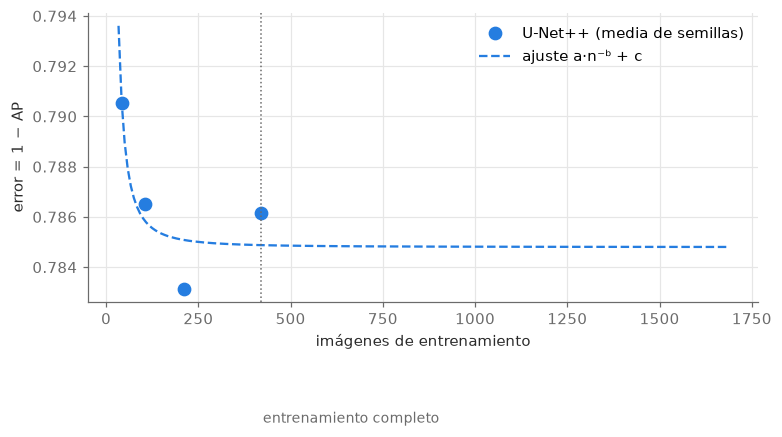

Ajuste: error(n) = 6.38·n^(−1.87) + 0.785. La asíntota c = 0.785 es el error que el ajuste atribuye a la arquitectura y a las anotaciones, y no se reduce con más imágenes. Duplicar el entrenamiento (842 imágenes) bajaría el error a 0.785 según el ajuste. Con cuatro puntos y tres parámetros, esa extrapolación es una indicación de tendencia, válida solo si las imágenes nuevas vienen de la misma distribución.

In [4]:
pl = R["ablations"].get("power_law")
if pl is not None and "b" in pl:
    pts = pl["points"]
    n = np.linspace(pts.n_train.min() * 0.8, 421 * 4, 200)
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.plot(pts.n_train, pts.error, "o", color=CAT[0], ms=8, label="U-Net++ (media de semillas)")
    ax.plot(n, pl["a"] * n ** (-pl["b"]) + pl["c"], color=CAT[0], lw=1.5, ls="--", label="ajuste a·n⁻ᵇ + c")
    ax.axvline(421, color=MUTED, lw=1, ls=":"); ax.text(425, ax.get_ylim()[1] * 0.98, "entrenamiento completo", color=MUTED, va="top", fontsize=9)
    ax.set(xlabel="imágenes de entrenamiento", ylabel="error = 1 − AP"); ax.legend()
    plt.show()
    display(Markdown(
        f"Ajuste: error(n) = {pl['a']:.2f}·n^(−{pl['b']:.2f}) + {pl['c']:.3f}. La asíntota c = {pl['c']:.3f} es el error que el ajuste "
        f"atribuye a la arquitectura y a las anotaciones, y no se reduce con más imágenes. Duplicar el entrenamiento (842 imágenes) bajaría "
        f"el error a {pl['a'] * 842 ** (-pl['b']) + pl['c']:.3f} según el ajuste. Con cuatro puntos y tres parámetros, esa extrapolación "
        f"es una indicación de tendencia, válida solo si las imágenes nuevas vienen de la misma distribución."))

## *Leave-one-cell-type-out* (cambio de dominio)

Entrenamos la U-Net++ sin un tipo celular y la evaluamos sobre las imágenes de test de ese tipo. La comparación es contra la U-Net++ principal en las mismas imágenes; la columna de semillas indica qué estadística respalda cada fila, con la misma regla que las ablaciones.

In [5]:
lo_ = R["locto"]
if len(lo_):
    t = seed_cols(lo_.assign(tipo=lo_.excluded.map(CELL_NAMES)))
    t["Δ AP [IC 95 % por imagen]"] = [ci(d, a, b) for d, a, b in zip(t["diff"], t.lo, t.hi)]
    cols = ["tipo", "n", "ap_main", "ap_locto", "Δ AP [IC 95 % por imagen]", "p", "nivel"]
    if (t.seeds >= 2).any():
        cols += ["Δ por semilla (mín. a máx.)", "mismo signo en todas"]
    display(t[cols].rename(columns={"n": "imágenes", "ap_main": "AP con el tipo en entrenamiento", "ap_locto": "AP sin el tipo",
                                    "p": "p (Wilcoxon)", "nivel": "semillas"}))
else:
    display(Markdown("Las corridas *leave-one-cell-type-out* no terminaron dentro del presupuesto."))

,tipo,imágenes,AP con el tipo en entrenamiento,AP sin el tipo,Δ AP [IC 95 % por imagen],p (Wilcoxon),semillas,Δ por semilla (mín. a máx.),mismo signo en todas
0,Astrocitos,21,0.077,0.035,"-0.041 [-0.055, -0.027]",5.245e-05,2 semillas,-0.044 a -0.038,sí
1,Corticales,48,0.298,0.175,"-0.123 [-0.144, -0.104]",7.105e-15,2 semillas,-0.131 a -0.113,sí
2,SH-SY5Y,24,0.166,0.048,"-0.118 [-0.138, -0.099]",1.192e-07,2 semillas,-0.121 a -0.113,sí


## Perturbaciones sintéticas

Aplicamos seis perturbaciones a las imágenes de test con cinco severidades cada una, en el estilo de ImageNet-C {cite:p}`hendrycks2019robustness`: ruido gaussiano, desenfoque, reducción de contraste, aumento de brillo, gradiente de iluminación y compresión JPEG. El post-proceso es el congelado en validación; las imágenes perturbadas no se vieron al elegirlo.

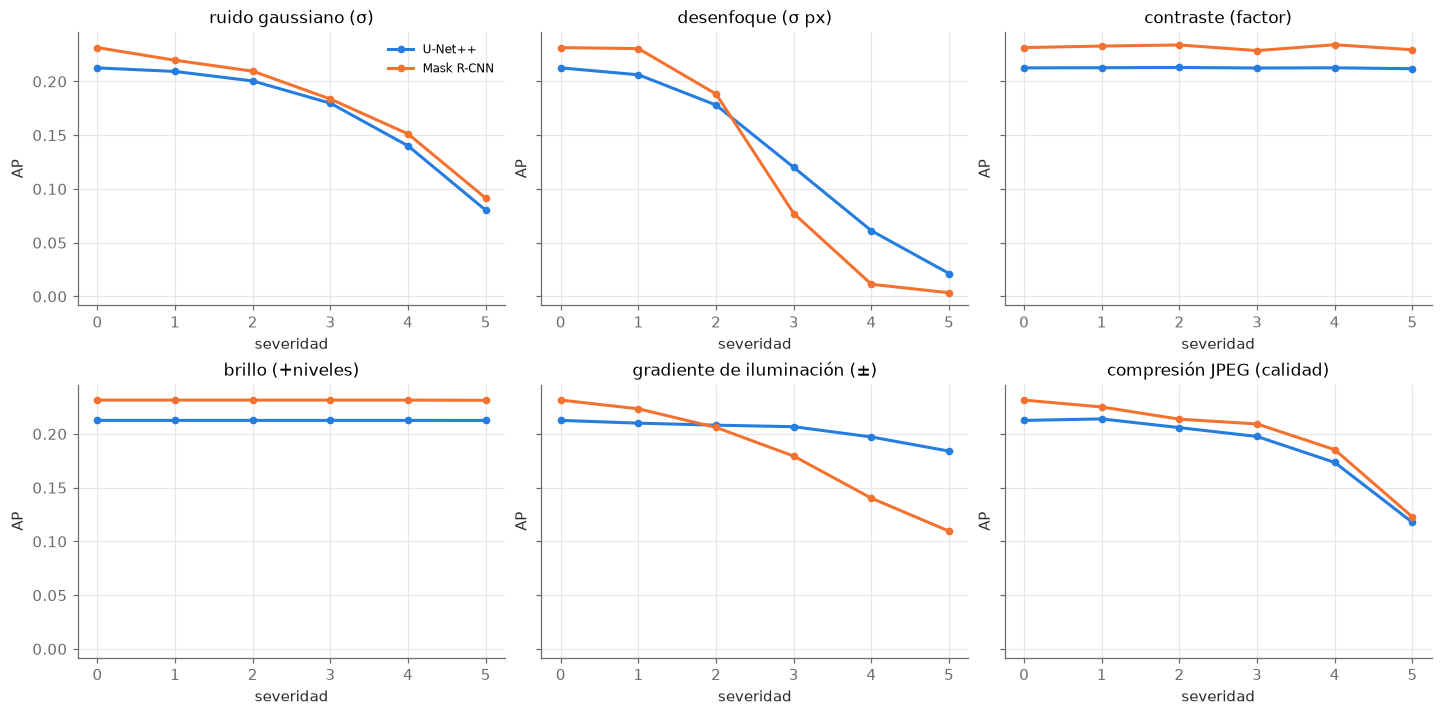

perturbation,brillo (+niveles),compresión JPEG (calidad),contraste (factor),desenfoque (σ px),gradiente de iluminación (±),ruido gaussiano (σ),media
model,,,,,,,
Mask R-CNN,0.0,0.174,-0.002,0.559,0.258,0.261,0.208
U-Net++,0.0,0.145,0.000,0.448,0.054,0.238,0.148


«contraste (factor)» y «brillo (+niveles)» no cambian el AP (caída menor que 0.01 en todos los modelos). Es una consecuencia del preprocesamiento, no una robustez aprendida: cada imagen se normaliza con sus propios percentiles (capítulo {doc}`11_seg_preprocesamiento`), y esa normalización deshace cualquier transformación afín de la intensidad mientras no sature píxeles. El gradiente de iluminación no es afín sobre toda la imagen y por eso sí afecta.

In [6]:
if exists("analysis/seg_perturb/rows.pkl"):
    P = pd.DataFrame(need("analysis/seg_perturb/rows.pkl"))
    base = P[P.perturbation == "ninguna"].groupby("model").ap.mean()
    kinds = [k for k in P.perturbation.unique() if k != "ninguna"]
    fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharey=True)
    for ax, k in zip(axes.ravel(), kinds):
        for j, m in enumerate(P.model.unique()):
            g = P[(P.model == m) & (P.perturbation == k)].groupby("severity").ap.mean()
            ax.plot([0, *g.index], [base[m], *g.values], "o-", color=CAT[j], ms=4, label=L.get(m, m))
        ax.set(title=k, xlabel="severidad", ylabel="AP")
    axes[0, 0].legend(fontsize=8)
    plt.show()
    # caída relativa media (mCE simplificado) por modelo
    drop = P[P.perturbation != "ninguna"].groupby(["model", "perturbation"]).ap.mean().unstack()
    rel = 1 - drop.div(base, axis=0)
    rel["media"] = rel.mean(1)
    display(rel.rename(index=L).round(3))
    _inv = [k for k in kinds if rel[k].abs().max() < 0.01]
    if _inv:
        display(Markdown(
            f"{' y '.join(f'«{k}»' for k in _inv)} no {'cambian' if len(_inv) > 1 else 'cambia'} el AP (caída menor que 0.01 en todos "
            "los modelos). Es una consecuencia del preprocesamiento, no una robustez aprendida: cada imagen se normaliza con sus propios "
            "percentiles (capítulo {doc}`11_seg_preprocesamiento`), y esa normalización deshace cualquier transformación afín de la "
            "intensidad mientras no sature píxeles. El gradiente de iluminación no es afín sobre toda la imagen y por eso sí afecta."))
else:
    display(Markdown("Las perturbaciones no terminaron dentro del presupuesto."))

La tabla da la caída relativa de AP promediada sobre las cinco severidades. Una caída de 0.3 significa que el modelo conserva el 70 % de su AP limpio.

## Aumento en inferencia (TTA) e incertidumbre por ensamble de semillas

TTA con volteos (3 vistas), U-Net++: AP sin TTA 0.214, con TTA 0.218; diferencia 0.004 [0.002, 0.006] (Wilcoxon p = 8.76e-08).

Ensamble de 3 semillas (media de probabilidades): AP 0.221; diferencia frente a la media de las semillas individuales 0.007 [0.005, 0.009]. Correlación media por imagen entre la varianza entre semillas de P(interior) y el error de píxel: 0.16.

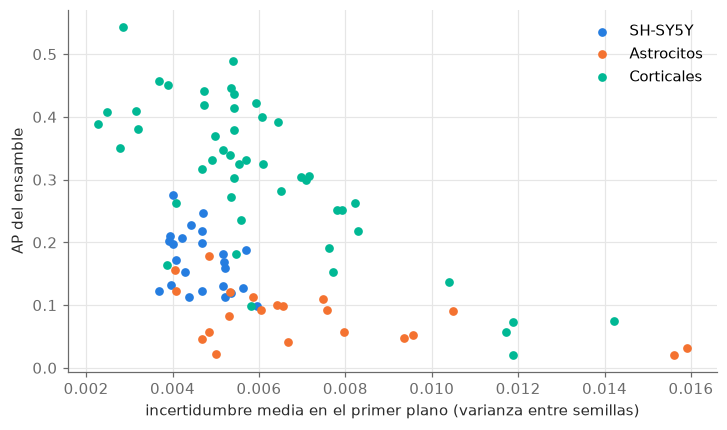

In [7]:
if exists("analysis/seg_tta/tta.pkl"):
    T = need("analysis/seg_tta/tta.pkl")
    r = T["rows"]
    d = r.groupby("id")[["ap", "ap_tta"]].mean()
    est, lo, hi = bootstrap_ci((d.ap_tta - d.ap).to_numpy())
    from project.stats import wilcoxon_p

    display(Markdown(f"TTA con volteos (3 vistas), U-Net++: AP sin TTA {d.ap.mean():.3f}, con TTA {d.ap_tta.mean():.3f}; "
                     f"diferencia {ci(est, lo, hi)} (Wilcoxon p = {wilcoxon_p(d.ap_tta, d.ap):.3g})."))
    E = T["ensemble"]
    single = r.groupby("id").ap.mean().reindex(E.id).to_numpy()
    est2, lo2, hi2 = bootstrap_ci(E.ap_ensemble.to_numpy() - single)
    display(Markdown(f"Ensamble de {int(E.n_seeds.max())} semillas (media de probabilidades): AP {E.ap_ensemble.mean():.3f}; "
                     f"diferencia frente a la media de las semillas individuales {ci(est2, lo2, hi2)}. "
                     f"Correlación media por imagen entre la varianza entre semillas de P(interior) y el error de píxel: "
                     f"{E.unc_err_corr.mean():.2f}."))
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    for t in ("shsy5y", "astro", "cort"):
        g = E[E.cell_type == t]
        ax.scatter(g.unc_fg, g.ap_ensemble, color=CELL_COLORS[t], label=CELL_NAMES[t], s=22)
    ax.set(xlabel="incertidumbre media en el primer plano (varianza entre semillas)", ylabel="AP del ensamble"); ax.legend()
    plt.show()
else:
    display(Markdown("El análisis de TTA no terminó dentro del presupuesto."))

Si la incertidumbre del ensamble sirve para priorizar revisión humana, las imágenes con mayor varianza entre semillas deberían tener menor AP. La dispersión por tipo celular muestra si esa relación vale dentro de cada tipo o solo refleja que un tipo es a la vez más difícil y más incierto.

## Calibración de la probabilidad de píxel

,modelo,ECE de píxel,Brier,píxeles muestreados
0,U-Net++,0.021,0.035,372000
1,Hover (NP+HV),0.026,0.036,372000
2,Mask R-CNN,0.047,0.059,372000
3,Cellpose cero-shot,0.064,0.137,372000
4,Cellpose ajustado,0.011,0.035,372000
5,SAM (cajas),0.059,0.067,372000
6,SAM automático,0.215,0.201,372000


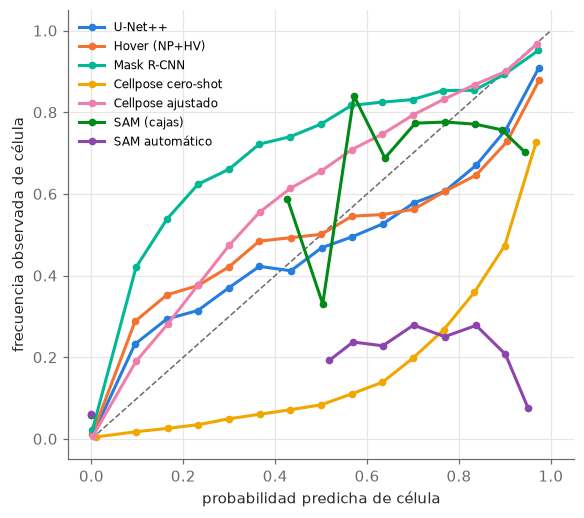

In [8]:
pc = R.get("pixel_calibration", {})
if pc and len(pc["table"]):
    display(pc["table"].assign(modelo=pc["table"].model.map(L))[["modelo", "ece", "brier", "n_pixels"]]
            .rename(columns={"ece": "ECE de píxel", "brier": "Brier", "n_pixels": "píxeles muestreados"}))
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
    for j, (m, rel) in enumerate(pc["reliability"].items()):
        ax.plot(rel.conf, rel.freq, "o-", ms=4, color=CAT[j], label=L.get(m, m))
    ax.set(xlabel="probabilidad predicha de célula", ylabel="frecuencia observada de célula"); ax.legend(fontsize=8)
    plt.show()

## Explicabilidad: Grad-CAM

Calculamos Grad-CAM {cite:p}`selvaraju2017gradcam` de la probabilidad media de «interior» dentro de las células de referencia respecto a tres capas de la U-Net++: el cuello de botella ($X^{4,0}$), un nodo intermedio del decodificador ($X^{3,1}$) y la última salida anidada ($X^{0,4}$). Dos imágenes de test por tipo celular, elegidas con semilla fija.

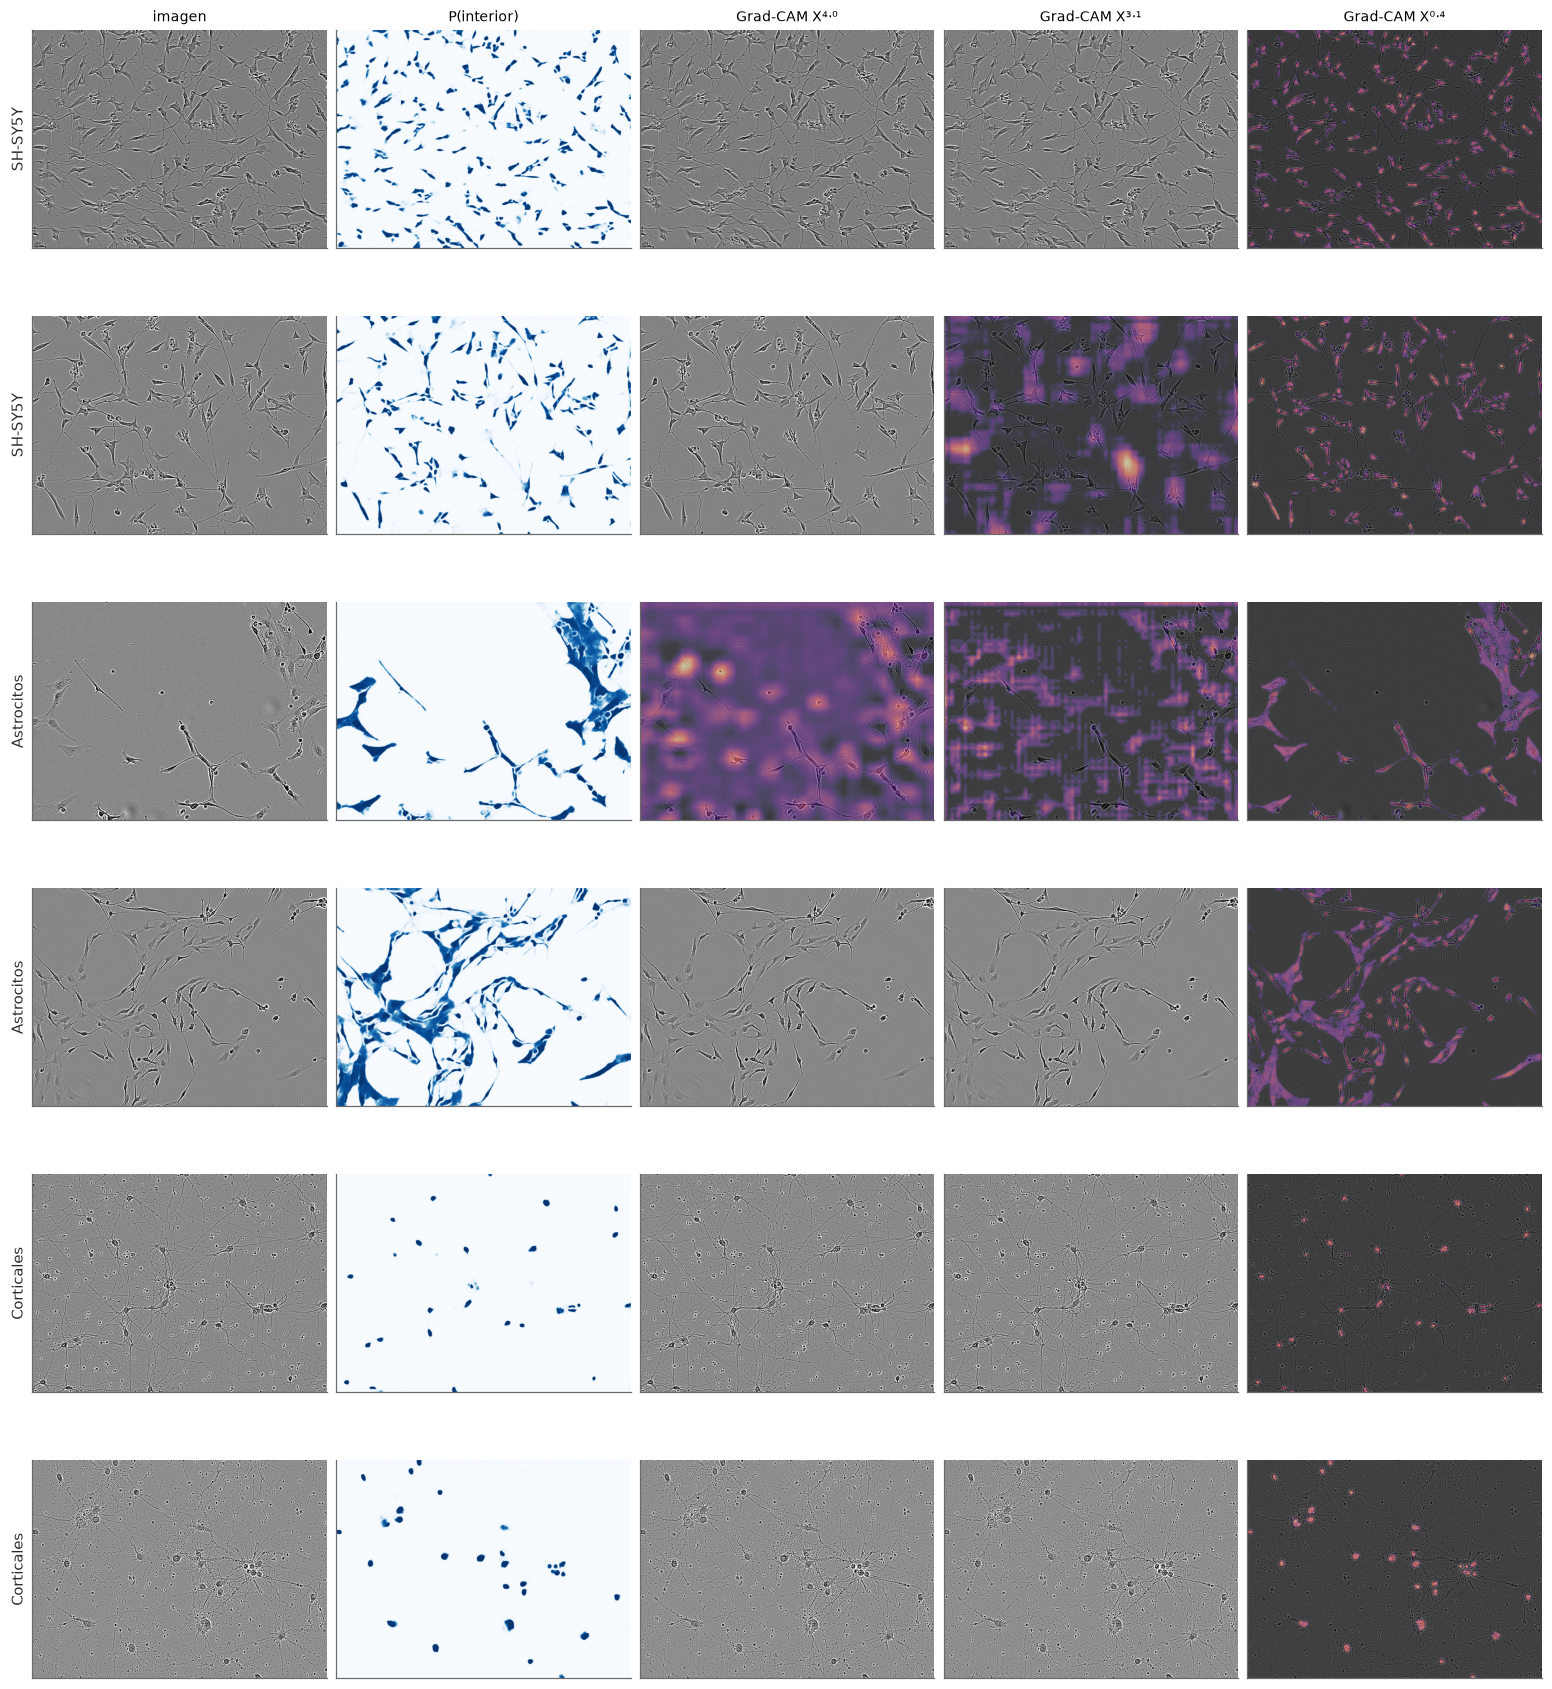

In [9]:
if exists("analysis/seg_gradcam/gradcam_meta.pkl"):
    from project.sartorius_data import normalize_percentile, read_image
    gm = need("analysis/seg_gradcam/gradcam_meta.pkl")
    from project.config import RESULTS
    z = np.load(RESULTS / "analysis" / "seg_gradcam" / "gradcam.npz")
    fig, axes = plt.subplots(len(gm["ids"]), 5, figsize=(14, 2.6 * len(gm["ids"])))
    for r_, (i, ct) in enumerate(zip(gm["ids"], gm["cell_types"])):
        axes[r_, 0].imshow(normalize_percentile(read_image(i)), cmap="gray"); axes[r_, 0].set_ylabel(CELL_NAMES[ct])
        axes[r_, 1].imshow(z[f"{i}__prob"].astype(float), cmap="Blues", vmin=0, vmax=1)
        for c, lay in enumerate(gm["layers"]):
            axes[r_, 2 + c].imshow(normalize_percentile(read_image(i)), cmap="gray")
            axes[r_, 2 + c].imshow(z[f"{i}__{lay}"].astype(float), cmap="magma", alpha=0.55, vmin=0, vmax=1)
    for ax, t in zip(axes[0], ["imagen", "P(interior)", "Grad-CAM X⁴·⁰", "Grad-CAM X³·¹", "Grad-CAM X⁰·⁴"]):
        ax.set_title(t, fontsize=9)
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([])
    plt.show()
else:
    display(Markdown("Grad-CAM no terminó dentro del presupuesto."))

Grad-CAM en segmentación responde a una pregunta distinta que en clasificación: qué regiones aumentan la probabilidad de «interior» agregada sobre las células. Una activación concentrada en las células y no en el fondo indica que la red usa la textura celular; una activación extendida al fondo indicaría que usa contexto global, como la densidad del cultivo. La resolución del cuello de botella (1/16 de la imagen) hace que su mapa sea grueso por construcción.

## Eficiencia

In [10]:
md = lambda t: display(Markdown(t))  # noqa: E731
if exists("analysis/seg_efficiency/efficiency.pkl"):
    ef = need("analysis/seg_efficiency/efficiency.pkl").copy()
    ef = ef[ef.model.isin(list(L)) & ~ef.model.str.contains("frac")]  # solo los modelos principales
    _ctl = ef[ef.gflops.notna()] if "gflops" in ef.columns else ef.iloc[:0]
    if exists("analysis/seg_efficiency_extra/efficiency_extra.pkl"):
        ex_ = need("analysis/seg_efficiency_extra/efficiency_extra.pkl")
        ex_ = ex_[ex_["error"].isna()] if "error" in ex_.columns else ex_
        ef = pd.concat([_ctl, ex_[~ex_.model.isin(_ctl.model)]], ignore_index=True)
        _todo = True
    else:
        _todo = False
    ef["modelo"] = ef.model.map(L)
    ef = ef.sort_values("lat_p50_ms")
    cols = [c for c in ["modelo", "params", "gflops", "peak_vram_mb", "lat_p50_ms", "lat_p95_ms", "throughput_img_s", "kwh_per_img",
                        "kg_co2_per_img"] if c in ef.columns]
    display(ef[cols].rename(columns={"params": "parámetros", "gflops": "GFLOPs", "peak_vram_mb": "VRAM pico (MB)", "lat_p50_ms": "latencia p50 (ms)",
                                     "lat_p95_ms": "latencia p95 (ms)", "throughput_img_s": "imágenes/s", "kwh_per_img": "kWh por imagen",
                                     "kg_co2_per_img": "kg CO₂e por imagen"})
            .style.hide(axis="index").format(precision=1, na_rep="—")
            .format({"parámetros": lambda v: "—" if pd.isna(v) else f"{v / 1e6:.1f} M"}))
    _sa = ef.set_index("model").lat_p50_ms
    md("Todas las filas comparten las condiciones de medición: 30 imágenes de test de 520 × 704, lote de una imagen, tres de "
       "calentamiento, sincronización de CUDA y post-proceso en CPU incluido, en la GPU RTX 4060 Laptop. "
       if _todo else "Solo las filas con GFLOPs tienen la medición controlada. ")
    if _todo and {"cellpose_finetune", "unetpp_main", "sam_auto"} <= set(_sa.index):
        md(f"Cellpose ajustado tarda {_sa['cellpose_finetune']:.0f} ms por imagen frente a {_sa['unetpp_main']:.0f} ms de la U-Net++. "
           "SAM automático, con una rejilla de "
           f"48 × 48 puntos, tarda {_sa['sam_auto'] / 1e3:.1f} s por imagen, lo que lo descarta para un uso interactivo aunque su AP "
           "fuera competitivo. La energía y el CO₂e solo los estimó codecarbon en la primera medición (filas con GFLOPs).")
else:
    display(Markdown("La medición de eficiencia no terminó dentro del presupuesto."))

modelo,parámetros,GFLOPs,VRAM pico (MB),latencia p50 (ms),latencia p95 (ms),imágenes/s,kWh por imagen,kg CO₂e por imagen
Otsu + watershed,0.0 M,nan,0.000000,124.857550,139.951310,7.938936,nan,nan
Hover (NP+HV),9.1 M,nan,2153.996288,201.567200,212.422220,4.965308,nan,nan
U-Net++,9.1 M,347.975057,2205.020160,408.792050,449.298480,2.422649,0.000006,0.000001
Mask R-CNN,45.9 M,1147.913810,2263.378944,439.164200,1062.769705,1.882202,0.000011,0.000002
Cellpose ajustado,6.6 M,nan,584.327168,478.717450,572.562690,2.062559,nan,nan
SAM (cajas),139.6 M,nan,4093.705216,720.711500,1577.893845,1.183352,nan,nan
Cellpose cero-shot,6.6 M,nan,612.401152,1296.667250,2478.863085,0.662425,nan,nan
SAM automático,93.7 M,nan,4680.651776,12696.367700,14484.082365,0.078548,nan,nan


Todas las filas comparten las condiciones de medición: 30 imágenes de test de 520 × 704, lote de una imagen, tres de calentamiento, sincronización de CUDA y post-proceso en CPU incluido, en la GPU RTX 4060 Laptop. 

Cellpose ajustado tarda 479 ms por imagen frente a 409 ms de la U-Net++. SAM automático, con una rejilla de 48 × 48 puntos, tarda 12.7 s por imagen, lo que lo descarta para un uso interactivo aunque su AP fuera competitivo. La energía y el CO₂e solo los estimó codecarbon en la primera medición (filas con GFLOPs).